In [1]:
from spectro_tomography import *
from energy_selection import *
from spectro_tomography_fast import multistate_tomo_joint_TV as mct_fast
import json
import os
import time

/nsls2/users/hyan/.local/share/pixi-envs/spectro-tomo-543182226939049188/envs/default/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


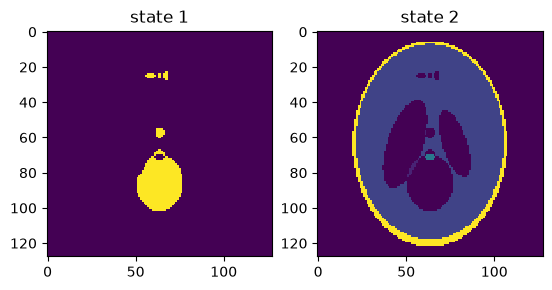

In [2]:
%matplotlib inline
obj_sz = 128
num_angle = 61
V = shepp_logan(obj_sz)
ind1 = np.where(np.abs(V-0.3)<0.01)
mask1 = np.zeros(V.shape)
mask1[ind1] = 1

ind2 = np.where(np.abs(V-0.3)>=0.01)
mask2 = np.zeros(V.shape)
mask2[ind2] = 1

im1 = V*mask1
im2 = V*mask2

plt.subplot(121)
plt.title('state 1')
plt.imshow(im1, interpolation='none')
plt.subplot(122)
plt.imshow(im2,interpolation='none')
plt.title('state 2')
plt.show()

Reconstruction iterations: 100%|█████████████| 100/100 [00:01<00:00, 60.37it/s]


mean square error = 4.48456221989648e-05
runing time is 1.9056437015533447


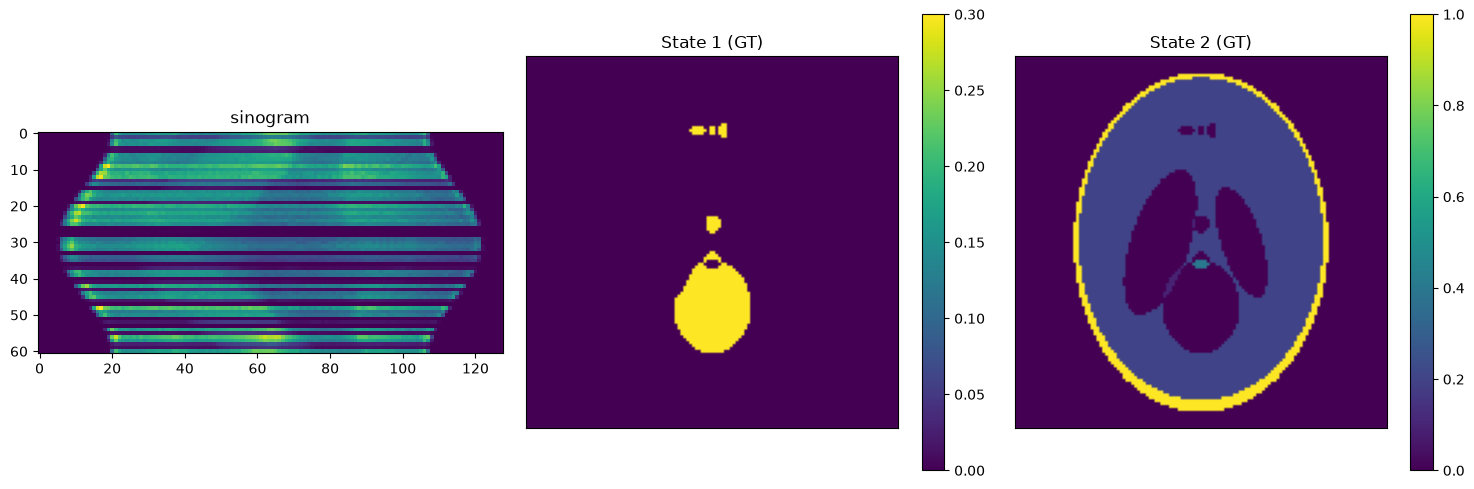

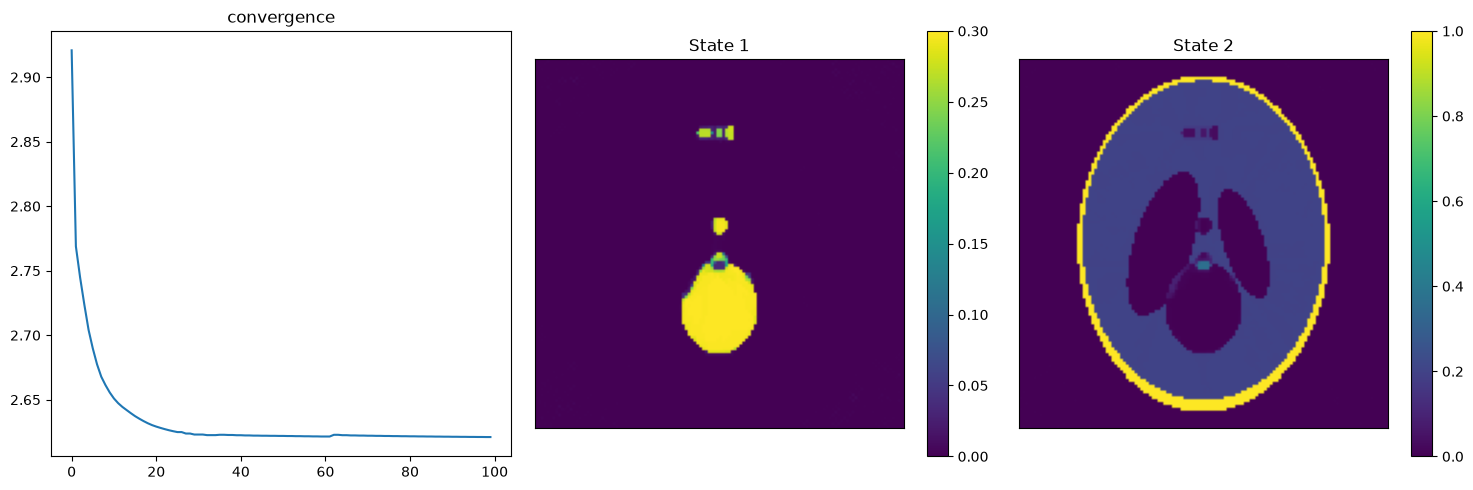

In [5]:
num_angle = 61

# im1 = tf.imread('Flower1_128.tif')
# im1 = im1/np.max(im1)

# im2 = tf.imread('Lotus_128.tif')
# im2 = im2/np.max(im2)

obj_row, obj_col = np.shape(V) 

ref_spectra = np.loadtxt('fe0_fe3_ref.txt')
used_spect = np.abs(ref_spectra[:,1:3])


# generate the list of angle-energy pairs and the codebook 
# that records the relative intensity change of each state based on reference spectra
# 'uniform-random' refers to uniform angular step and random energy selection
# other options used in the paper are 'uniform-interlaced' and 'uniform-segmented'

angle, codebook, ind = generate_plan(used_spect,[0,np.pi],num_angle,'uniform-random')
angle = np.linspace(0,np.pi,num_angle)
sino = []

for i in range (len(angle)):
    proj_geom = astra.create_proj_geom('parallel',1.0,obj_col,angle[i])
    vol_geom = astra.create_vol_geom(obj_row,obj_col)
    proj_id = astra.create_projector('linear',proj_geom,vol_geom)
    [sigogram_id, sinogram] = astra.create_sino(im1*codebook[i,0]+im2*codebook[i,1],proj_id)
    sino.append(sinogram)
sino = np.squeeze(np.array(sino))
# sino_noise=np.random.poisson(np.array(sino*1e3/np.max(sino),dtype='int'))/1e3

# random initialization
x_init = []
x_init.append(np.random.rand(obj_row,obj_col))
x_init.append(np.random.rand(obj_row,obj_col))

# x_init.append(np.random.rand(obj_row,obj_col)*0.2 + im1)
# x_init.append(np.random.rand(obj_row,obj_col)*0.2 + im2)
 
mu1 = 0.02
mu2 = 1
mu3=0.2
itr_num = 100
rot_offset = 0

start_time= time.time()
rec,err = mct_fast(sinogram=sino,
                   angle=angle,
                   rot_cen_offset=rot_offset,
                   obj_size=[obj_row,obj_col],
                   ref=codebook,
                   mu1=mu1,
                   mu2=mu2,
                   mu3=mu3,
                   max_iter=itr_num,
                   nonnegative=False,
                   x0=x_init,
                   regularization='TV+L1',
                   backend="gpu",
                   algorithm="admm",
                   method="gmres",
                   seq_save=True)

end_time = time.time()
rec_mse = mse(im1,rec[-1][0]) + mse(im2,rec[-1][1])
print(f"mean square error = {rec_mse}")
print(f"runing time is {end_time - start_time}")

plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(sino)
plt.title('sinogram')
plt.subplot(132)
plt.imshow(im1,clim=[0,0.3])
plt.colorbar()
plt.title('State 1 (GT)')
plt.xticks([])
plt.yticks([])
plt.subplot(133)
plt.imshow(im2,clim=[0,1])
plt.colorbar()
plt.title('State 2 (GT)')
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.plot(np.log10(err))
plt.title('convergence')
plt.subplot(132)
plt.imshow(rec[-1][0],clim=[0,0.3])
plt.colorbar()
plt.title('State 1')
plt.xticks([])
plt.yticks([])
plt.subplot(133)
plt.imshow(rec[-1][1],clim=[0,1])
plt.colorbar()
plt.title('State 2')
plt.xticks([])
plt.yticks([])
plt.tight_layout()

data_size = 7808, rec_size = 32768


100%|████████████████████████████████████████| 100/100 [01:13<00:00,  1.35it/s]


mean square error = 0.005806879540274175
runing time is 73.96497702598572


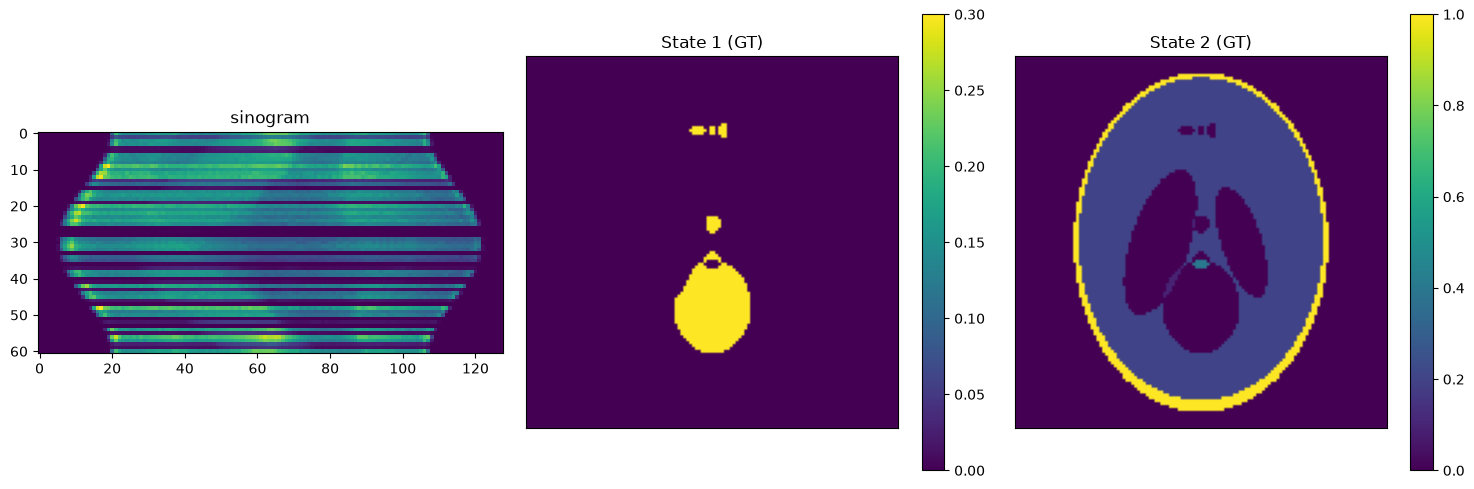

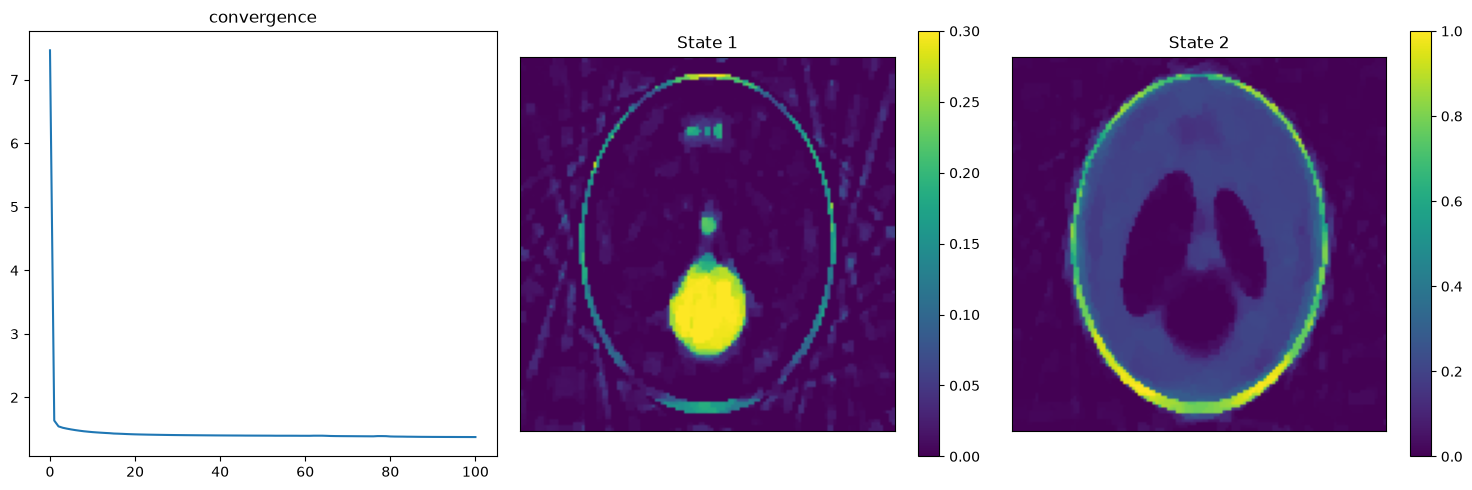

In [6]:

start_time= time.time()
rec,err = multistate_tomo_joint_TV(sinogram=sino,
                                   angle=angle,
                                   rot_cen_offset=0,
                                   obj_size=[obj_row,obj_col],
                                   ref=codebook,
                                   mu1=mu1,
                                   mu2=mu2,
                                   max_iter=itr_num,
                                   x0=x_init,
                                   method="gmres",
                                   seq_save=True)

end_time = time.time()
rec_mse = mse(im1,rec[-1][0]) + mse(im2,rec[-1][1])
print(f"mean square error = {rec_mse}")
print(f"runing time is {end_time - start_time}")

plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(sino)
plt.title('sinogram')
plt.subplot(132)
plt.imshow(im1,clim=[0,0.3])
plt.colorbar()
plt.title('State 1 (GT)')
plt.xticks([])
plt.yticks([])
plt.subplot(133)
plt.imshow(im2,clim=[0,1])
plt.colorbar()
plt.title('State 2 (GT)')
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.plot(np.log10(err))
plt.title('convergence')
plt.subplot(132)
plt.imshow(rec[-1][0],clim=[0,0.3])
plt.colorbar()
plt.title('State 1')
plt.xticks([])
plt.yticks([])
plt.subplot(133)
plt.imshow(rec[-1][1],clim=[0,1])
plt.colorbar()
plt.title('State 2')
plt.xticks([])
plt.yticks([])
plt.tight_layout()